# Ejercicio - Mutual Information y ANOVA

Analizar el dataset `anova_05.csv`.

El objetivo es estudiar la relación entre variables continuas y una variable categórica objetivo.

En este caso, la variable objetivo es:

- `y`: variable categórica.

Y las variables continuas a analizar son:

- `x1`
- `x2`
- `x3`
- `x4`

La consigna pide aplicar:

1. **Mutual Information** para todos los casos posibles de análisis entre una variable continua y una variable categórica objetivo.
2. **ANOVA** solamente en aquellos casos en los que se cumplan las condiciones necesarias para su uso.
3. Realizar gráficos.
4. Redactar conclusiones significativas para todos los casos analizados.


## Objetivo del análisis

El objetivo principal es determinar si las variables continuas del dataset aportan información o presentan diferencias relevantes respecto de una variable categórica objetivo.

Variable objetivo será:

- `y`

Y las variables continuas serán aquellas columnas numéricas disponibles en el dataset.

Se busca responder preguntas como:

- ¿Qué variables continuas aportan más información para distinguir las categorías de `y`?
- ¿Las distribuciones de las variables continuas cambian según la categoría de `y`?
- ¿Existen diferencias estadísticamente significativas entre las medias de los grupos?
- ¿En qué casos corresponde aplicar ANOVA y en qué casos no?

## Mutual Information

La **Mutual Information** es una medida que permite evaluar cuánta información aporta una variable para explicar otra.

En este análisis se utilizará para medir cuánto aporta cada variable continua para distinguir las categorías de la variable objetivo `y`.

Su interpretación general es:

- Un valor cercano a 0 indica que la variable aporta poca o ninguna información sobre la variable objetivo.
- Un valor mayor indica que la variable aporta más información para diferenciar las categorías de la variable objetivo.

Una ventaja de Mutual Information es que puede aplicarse a todos los casos de análisis entre una variable continua y una variable categórica, ya que no exige condiciones previas como normalidad u homogeneidad de varianzas.

## ANOVA

La prueba **ANOVA** permite comparar las medias de una variable continua entre dos o más grupos.

En este caso, se utilizará para analizar si el promedio de una variable continua cambia significativamente según las categorías de `y`.

Sin embargo, ANOVA solo debe aplicarse cuando se cumplen ciertas condiciones:

1. **Independencia de las observaciones**  
   Cada observación debe ser independiente de las demás.

2. **Normalidad dentro de cada grupo**  
   Los valores de la variable continua deberían aproximarse a una distribución normal dentro de cada categoría de `y`.

3. **Homogeneidad de varianzas**  
   Las varianzas de los grupos deben ser similares.

Para verificar estas condiciones se usarán:

- Prueba de Shapiro-Wilk para normalidad.
- Prueba de Levene para homogeneidad de varianzas.

El nivel de significancia utilizado será:

`alpha = 0.05`

In [3]:
# Librerias
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

from scipy.stats import shapiro
from scipy.stats import levene
from scipy.stats import f_oneway

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

sns.set(style="whitegrid")

In [4]:
# Dataset
df = pd.read_csv("/content/anova_05.csv")

print("Cantidad de filas y columnas:", df.shape)

df.head()

Cantidad de filas y columnas: (5000, 5)


,x1,x2,x3,x4,y
0,3.486216,15.956291,19.442507,14.775933,A
1,15.984073,19.533312,35.517384,15.211183,C
2,11.697871,11.590120,23.287991,7.863467,B
3,0.962232,16.927380,17.889611,4.493153,A
4,6.528398,11.616355,18.144753,10.339219,B


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      5000 non-null   float64
 1   x2      5000 non-null   float64
 2   x3      5000 non-null   float64
 3   x4      5000 non-null   float64
 4   y       5000 non-null   object 
dtypes: float64(4), object(1)
memory usage: 195.4+ KB


In [6]:
df.isnull().sum()

,0
x1,0
x2,0
x3,0
x4,0
y,0


In [7]:
df["y"].value_counts()

,count
y,
B,1892
C,1880
A,1228


## Identificación de variables

En esta etapa se identifica la variable categórica objetivo y las variables continuas a analizar.

La variable objetivo será:

- `y`

Las variables continuas serán aquellas columnas numéricas del dataset.

Cada variable continua será analizada en relación con `y`.

In [8]:
variable_objetivo = "y"

variables_continuas = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Variable objetivo:", variable_objetivo)
print("Variables continuas a analizar:", variables_continuas)

Variable objetivo: y
Variables continuas a analizar: ['x1', 'x2', 'x3', 'x4']


# Parte 1 - Aplicación de Mutual Information

Se aplica Mutual Information entre cada variable continua y la variable categórica objetivo `y`.

Este análisis se realiza para todos los casos posibles, ya que Mutual Information no requiere verificar supuestos previos.

El resultado permitirá ordenar las variables continuas según el nivel de información que aportan respecto de la variable objetivo.

In [9]:
X = df[variables_continuas]
y = df[variable_objetivo]

# Codificamos la variable categórica objetivo
encoder = LabelEncoder()
y_codificada = encoder.fit_transform(y)

print("Categorías originales de y:", encoder.classes_)
print("Categorías codificadas:", np.unique(y_codificada))

Categorías originales de y: ['A' 'B' 'C']
Categorías codificadas: [0 1 2]


In [10]:
# Mutual Info
mi_scores = mutual_info_classif(
    X,
    y_codificada,
    random_state=42
)

df_mi = pd.DataFrame({
    "Variable": variables_continuas,
    "Mutual Information": mi_scores
})

df_mi = df_mi.sort_values("Mutual Information", ascending=False)

df_mi

,Variable,Mutual Information
0,x1,1.079813
2,x3,0.523411
1,x2,0.016209
3,x4,0.011546


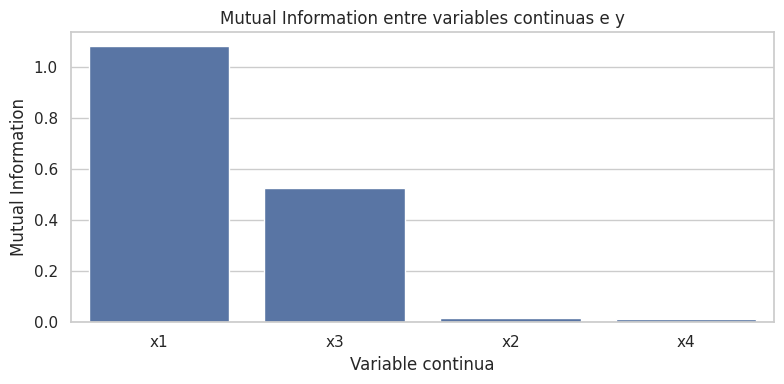

In [11]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=df_mi,
    x="Variable",
    y="Mutual Information"
)

plt.title("Mutual Information entre variables continuas e y")
plt.xlabel("Variable continua")
plt.ylabel("Mutual Information")
plt.tight_layout()
plt.show()

## Respuesta a la consigna: Mutual Information

Se aplicó Mutual Information para todos los casos posibles de análisis entre una variable continua y la variable categórica objetivo `y`.

El resultado obtenido permite observar qué variables continuas aportan mayor información para distinguir las categorías de `y`.

Las variables con valores más altos de Mutual Information serán consideradas como las más informativas respecto de la variable objetivo.

Estos resultados deberán interpretarse junto con los gráficos y, posteriormente, con las conclusiones redactadas.

# Parte 2 - Gráficos exploratorios

Antes de aplicar ANOVA, se realizan gráficos para observar el comportamiento de cada variable continua según las categorías de `y`.

Se utilizarán:

1. **Boxplots**, para comparar medianas, dispersión y posibles valores atípicos.
2. **Histogramas**, para observar la forma de las distribuciones.
3. **Gráficos de medias**, para comparar visualmente el promedio de cada grupo.

Estos gráficos ayudan a interpretar si las variables parecen comportarse de manera diferente según la categoría de la variable objetivo.

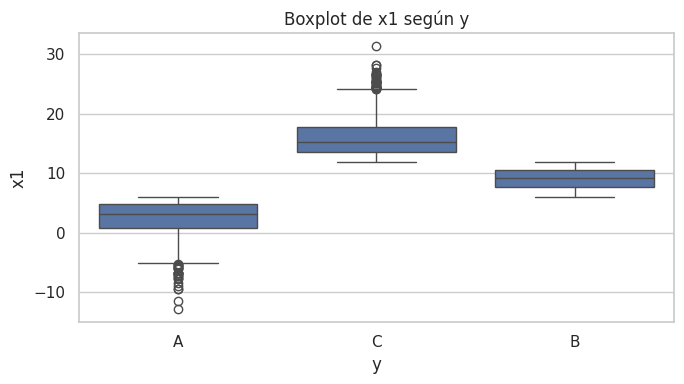

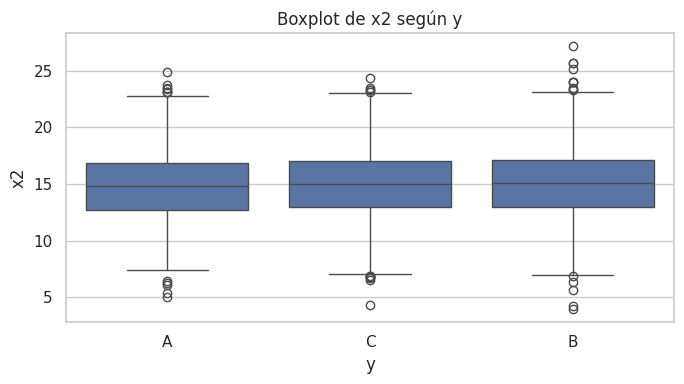

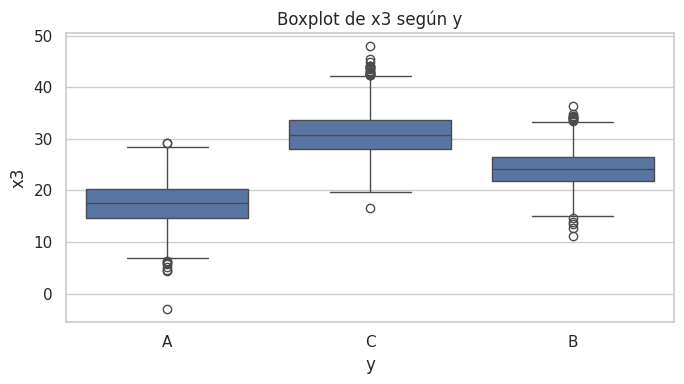

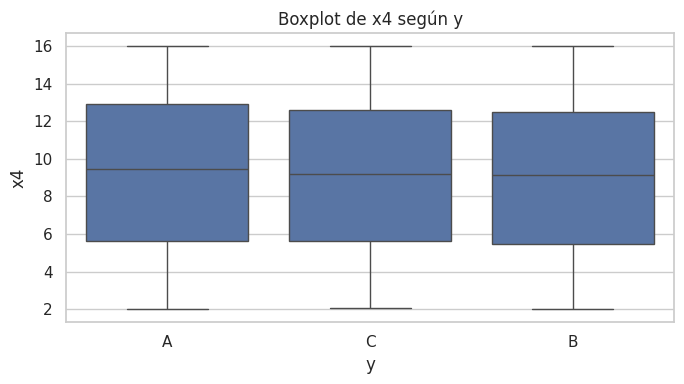

In [12]:
for variable in variables_continuas:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x=variable_objetivo,
        y=variable
    )

    plt.title(f"Boxplot de {variable} según {variable_objetivo}")
    plt.xlabel(variable_objetivo)
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()

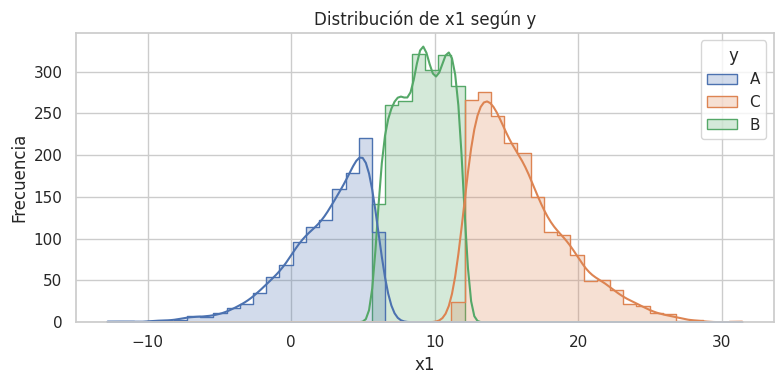

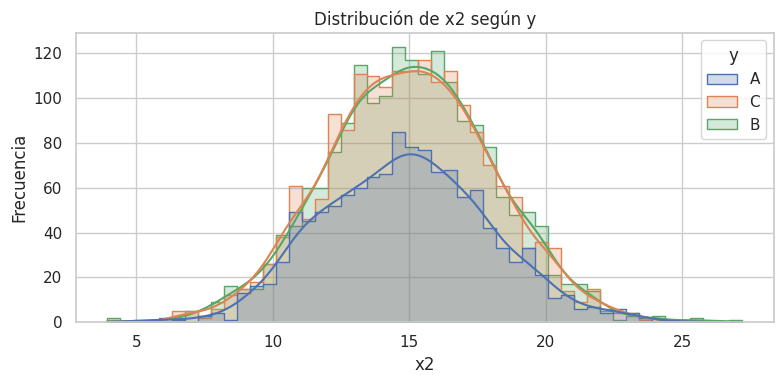

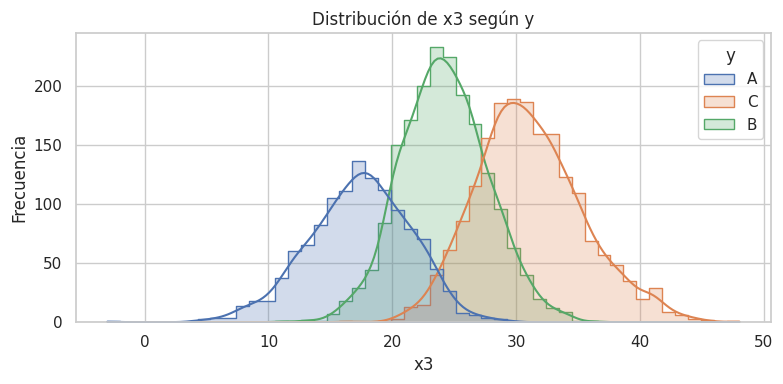

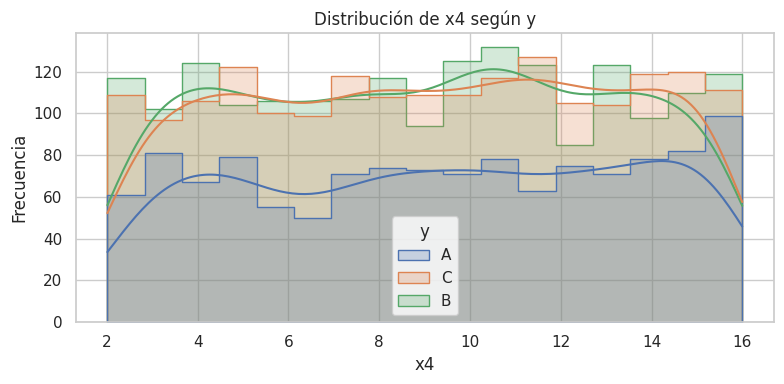

In [13]:
for variable in variables_continuas:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=variable,
        hue=variable_objetivo,
        kde=True,
        element="step"
    )

    plt.title(f"Distribución de {variable} según {variable_objetivo}")
    plt.xlabel(variable)
    plt.ylabel("Frecuencia")
    plt.tight_layout()
    plt.show()

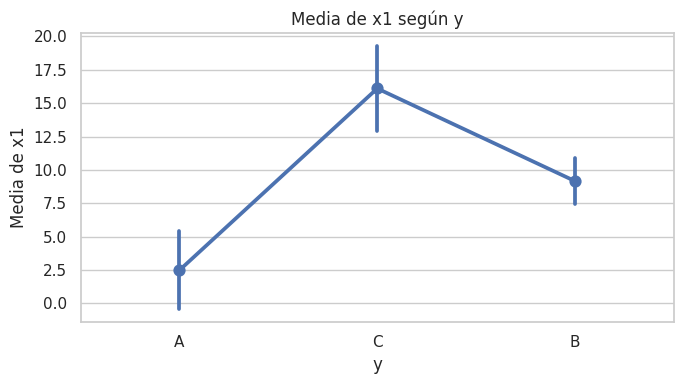

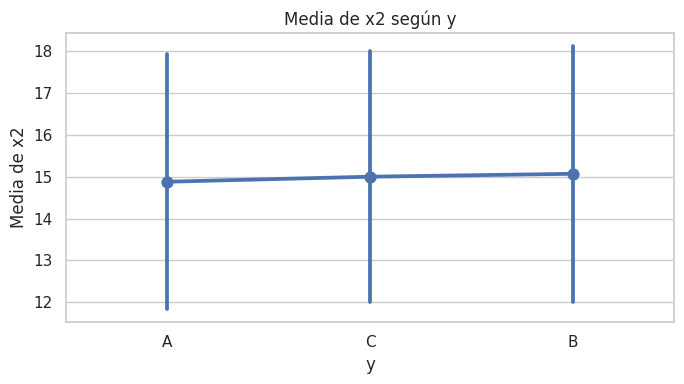

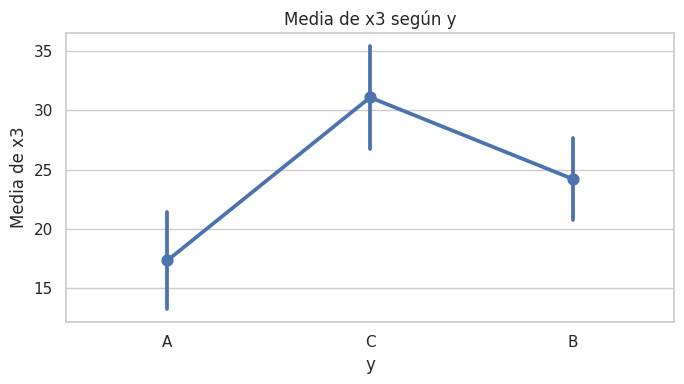

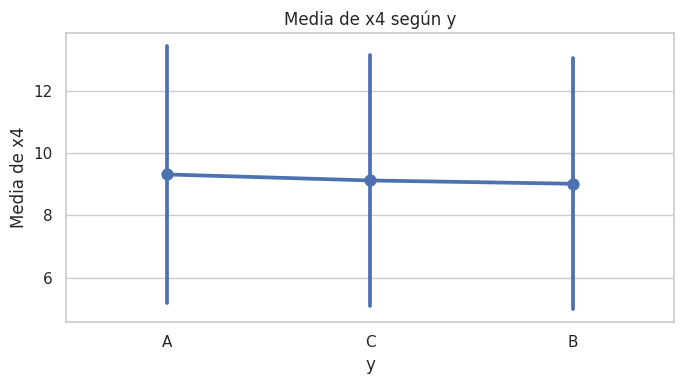

In [14]:
for variable in variables_continuas:

    plt.figure(figsize=(7, 4))

    sns.pointplot(
        data=df,
        x=variable_objetivo,
        y=variable,
        errorbar="sd"
    )

    plt.title(f"Media de {variable} según {variable_objetivo}")
    plt.xlabel(variable_objetivo)
    plt.ylabel(f"Media de {variable}")
    plt.tight_layout()
    plt.show()

# Parte 3 - Verificación de condiciones para ANOVA

Antes de aplicar ANOVA, se deben verificar las condiciones necesarias.

Para cada variable continua se analizará:

## 1. Normalidad por grupo

Se utilizará la prueba de Shapiro-Wilk.

Hipótesis:

- H0: los datos del grupo siguen una distribución normal.
- H1: los datos del grupo no siguen una distribución normal.

Regla de decisión:

- Si `p-value >= 0.05`, no se rechaza H0. Se considera que el grupo cumple normalidad.
- Si `p-value < 0.05`, se rechaza H0. Se considera que el grupo no cumple normalidad.

## 2. Homogeneidad de varianzas

Se utilizará la prueba de Levene.

Hipótesis:

- H0: las varianzas de los grupos son iguales.
- H1: al menos una varianza es diferente.

Regla de decisión:

- Si `p-value >= 0.05`, no se rechaza H0. Se considera que se cumple homogeneidad de varianzas.
- Si `p-value < 0.05`, se rechaza H0. Se considera que no se cumple homogeneidad de varianzas.

Solo se aplicará ANOVA en aquellas variables que cumplan ambas condiciones.

In [15]:
alpha = 0.05

def evaluar_condiciones_anova(variable):

    grupos = []
    resultados_normalidad = []

    categorias = df[variable_objetivo].unique()

    for categoria in categorias:

        datos_grupo = df[df[variable_objetivo] == categoria][variable].dropna()
        grupos.append(datos_grupo)

        stat_shapiro, p_shapiro = shapiro(datos_grupo)

        resultados_normalidad.append({
            "Variable": variable,
            "Grupo": categoria,
            "Shapiro estadístico": stat_shapiro,
            "Shapiro p-value": p_shapiro,
            "Cumple normalidad": "Sí" if p_shapiro >= alpha else "No"
        })

    stat_levene, p_levene = levene(*grupos)

    cumple_normalidad = all(
        resultado["Shapiro p-value"] >= alpha
        for resultado in resultados_normalidad
    )

    cumple_homogeneidad = p_levene >= alpha

    resultado_general = {
        "Variable": variable,
        "Cumple normalidad en todos los grupos": "Sí" if cumple_normalidad else "No",
        "Levene estadístico": stat_levene,
        "Levene p-value": p_levene,
        "Cumple homogeneidad de varianzas": "Sí" if cumple_homogeneidad else "No",
        "Se puede aplicar ANOVA": "Sí" if cumple_normalidad and cumple_homogeneidad else "No"
    }

    return resultados_normalidad, resultado_general

In [16]:
lista_normalidad = []
lista_condiciones = []

for variable in variables_continuas:

    resultados_normalidad, resultado_general = evaluar_condiciones_anova(variable)

    lista_normalidad.extend(resultados_normalidad)
    lista_condiciones.append(resultado_general)

df_normalidad = pd.DataFrame(lista_normalidad)
df_condiciones = pd.DataFrame(lista_condiciones)

print("Resultados de normalidad por grupo:")
display(df_normalidad)

print("Resumen de condiciones para ANOVA:")
display(df_condiciones)

Resultados de normalidad por grupo:


,Variable,Grupo,Shapiro estadístico,Shapiro p-value,Cumple normalidad
0,x1,A,0.900905,1.866325e-27,No
1,x1,C,0.916497,5.209794e-31,No
2,x1,B,0.958262,7.044763e-23,No
3,x2,A,0.997892,1.192039e-01,Sí
4,x2,C,0.999383,8.250757e-01,Sí
5,x2,B,0.999273,6.936495e-01,Sí
6,x3,A,0.994885,3.470485e-04,No
7,x3,C,0.990847,1.717463e-09,No
8,x3,B,0.998953,3.367494e-01,Sí
9,x4,A,0.948655,2.826746e-20,No


Resumen de condiciones para ANOVA:


,Variable,Cumple normalidad en todos los grupos,Levene estadístico,Levene p-value,Cumple homogeneidad de varianzas,Se puede aplicar ANOVA
0,x1,No,176.560401,8.107457e-75,No,No
1,x2,Sí,0.091406,9.126487e-01,Sí,Sí
2,x3,No,34.859915,9.229419e-16,No,No
3,x4,No,1.013055,3.631825e-01,Sí,No


In [17]:
variables_para_anova = df_condiciones[
    df_condiciones["Se puede aplicar ANOVA"] == "Sí"
]["Variable"].tolist()

variables_no_anova = df_condiciones[
    df_condiciones["Se puede aplicar ANOVA"] == "No"
]["Variable"].tolist()

print("Variables en las que SÍ se puede aplicar ANOVA:")
print(variables_para_anova)

print("\nVariables en las que NO corresponde aplicar ANOVA:")
print(variables_no_anova)

Variables en las que SÍ se puede aplicar ANOVA:
['x2']

Variables en las que NO corresponde aplicar ANOVA:
['x1', 'x3', 'x4']


## Respuesta a la consigna: condiciones de ANOVA

Se evaluaron las condiciones necesarias para aplicar ANOVA en cada variable continua.

Para cada variable se verificó:

- Normalidad en los grupos mediante Shapiro-Wilk.
- Homogeneidad de varianzas mediante Levene.

ANOVA se aplicará únicamente en aquellas variables que cumplan ambas condiciones.

Las variables que no cumplan estas condiciones no serán analizadas mediante ANOVA, ya que no corresponde aplicar esta prueba cuando sus supuestos principales no se verifican.

# Parte 4 - Aplicación de ANOVA

En esta parte se aplica ANOVA solamente a las variables que cumplieron las condiciones necesarias.

ANOVA permite analizar si existen diferencias estadísticamente significativas entre las medias de los grupos definidos por la variable categórica `y`.

## Hipótesis de ANOVA

### Hipótesis nula

H0: las medias de los grupos son iguales.

Esto significa que la variable continua no presenta diferencias significativas entre las categorías de `y`.

### Hipótesis alternativa

H1: al menos una media es diferente.

Esto significa que la variable continua sí presenta diferencias significativas entre al menos dos categorías de `y`.

## Regla de decisión

Con un nivel de significancia de `alpha = 0.05`:

- Si `p-value < 0.05`, se rechaza H0.
- Si `p-value >= 0.05`, no se rechaza H0.

In [18]:
def aplicar_anova(variable):

    grupos = []

    for categoria in df[variable_objetivo].unique():
        datos_grupo = df[df[variable_objetivo] == categoria][variable].dropna()
        grupos.append(datos_grupo)

    f_stat, p_value = f_oneway(*grupos)

    resultado = {
        "Variable": variable,
        "F estadístico": f_stat,
        "p_value": p_value,
        "Diferencia significativa": "Sí" if p_value < alpha else "No"
    }

    return resultado

In [19]:
resultados_anova = []

for variable in variables_para_anova:
    resultado = aplicar_anova(variable)
    resultados_anova.append(resultado)

df_anova = pd.DataFrame(resultados_anova)

if len(df_anova) > 0:
    df_anova = df_anova.sort_values("p_value")
    display(df_anova)
else:
    print("No hay variables que cumplan las condiciones necesarias para aplicar ANOVA.")

,Variable,F estadístico,p_value,Diferencia significativa
0,x2,1.459283,0.232502,No


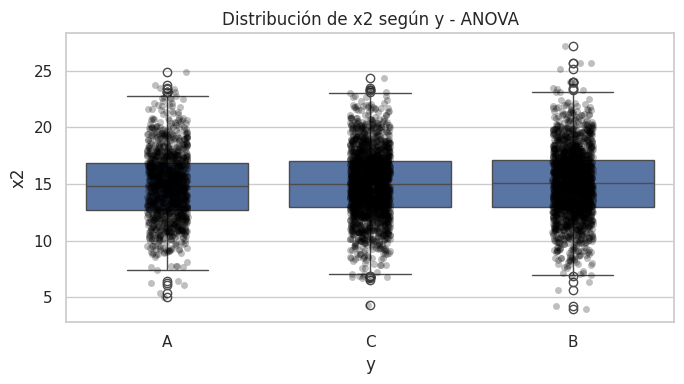

In [20]:
for variable in variables_para_anova:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x=variable_objetivo,
        y=variable
    )

    sns.stripplot(
        data=df,
        x=variable_objetivo,
        y=variable,
        color="black",
        alpha=0.25
    )

    plt.title(f"Distribución de {variable} según {variable_objetivo} - ANOVA")
    plt.xlabel(variable_objetivo)
    plt.ylabel(variable)
    plt.tight_layout()
    plt.show()

In [21]:
for variable in variables_continuas:

    print("="*70)
    print(f"Estadísticos descriptivos de {variable} según {variable_objetivo}")

    tabla_descriptiva = df.groupby(variable_objetivo)[variable].agg(
        media="mean",
        mediana="median",
        desvio="std",
        minimo="min",
        maximo="max",
        cantidad="count"
    )

    display(tabla_descriptiva.round(4))

Estadísticos descriptivos de x1 según y


,media,mediana,desvio,minimo,maximo,cantidad
y,,,,,,
A,2.4781,3.1884,2.9108,-12.8083,5.9992,1228
B,9.1547,9.2114,1.6999,6.0049,11.9997,1892
C,16.1003,15.3538,3.1841,12.0053,31.4295,1880


Estadísticos descriptivos de x2 según y


,media,mediana,desvio,minimo,maximo,cantidad
y,,,,,,
A,14.8782,14.8630,3.0371,5.0520,24.9352,1228
B,15.0674,15.0483,3.0479,3.9435,27.2043,1892
C,14.9985,15.0110,2.9930,4.2893,24.4087,1880


Estadísticos descriptivos de x3 según y


,media,mediana,desvio,minimo,maximo,cantidad
y,,,,,,
A,17.3563,17.5055,4.1054,-3.0258,29.2717,1228
B,24.2221,24.1035,3.4884,11.1122,36.3609,1892
C,31.0988,30.7690,4.3349,16.5617,48.0540,1880


Estadísticos descriptivos de x4 según y


,media,mediana,desvio,minimo,maximo,cantidad
y,,,,,,
A,9.3165,9.4605,4.1327,2.0149,15.9932,1228
B,9.0169,9.1584,4.0323,2.0135,15.9950,1892
C,9.1231,9.2029,4.0258,2.0469,15.9851,1880


# Conclusiones del análisis

El dataset analizado contiene 5000 observaciones y 5 variables: cuatro variables continuas (`x1`, `x2`, `x3`, `x4`) y una variable categórica objetivo (`y`). La variable objetivo presenta tres categorías: `A`, `B` y `C`. La categoría con mayor cantidad de registros es `B` con 1892 casos, seguida por `C` con 1880 casos y `A` con 1228 casos. No se observaron valores faltantes, por lo que fue posible trabajar con la totalidad del dataset.

## Conclusiones sobre Mutual Information

Se aplicó Mutual Information para analizar todos los casos posibles entre cada variable continua y la variable categórica objetivo `y`.

Los resultados obtenidos fueron:

- `x1`: Mutual Information = 1.079813
- `x3`: Mutual Information = 0.523411
- `x2`: Mutual Information = 0.016209
- `x4`: Mutual Information = 0.011546

A partir de estos valores, se observa que la variable `x1` es la que mayor información aporta para distinguir las categorías de `y`. Su valor de Mutual Information es considerablemente más alto que el del resto de las variables, lo que indica una fuerte asociación informativa entre `x1` y la variable objetivo.

En segundo lugar aparece `x3`, con un valor de Mutual Information también relevante. Si bien su aporte informativo es menor que el de `x1`, sigue mostrando una relación clara con las categorías de `y`.

En cambio, las variables `x2` y `x4` presentan valores de Mutual Information muy cercanos a cero. Esto indica que aportan muy poca información para diferenciar las categorías de la variable objetivo. Por lo tanto, desde este análisis, `x2` y `x4` parecen tener baja capacidad explicativa respecto de `y`.

En síntesis, según Mutual Information, las variables más importantes para distinguir las categorías de `y` son `x1` y `x3`, mientras que `x2` y `x4` muestran un aporte informativo muy bajo.

## Conclusiones a partir de los gráficos

Los gráficos permiten complementar la interpretación de Mutual Information.

En el caso de `x1`, los boxplots y las distribuciones muestran una separación muy clara entre las categorías de `y`. La categoría `A` presenta los valores más bajos, con una media de 2.4781; la categoría `B` se ubica en una zona intermedia, con una media de 9.1547; y la categoría `C` presenta los valores más altos, con una media de 16.1003. Esta separación visual explica por qué `x1` obtuvo el mayor valor de Mutual Information.

En el caso de `x3`, también se observa una diferencia clara entre los grupos. La categoría `A` presenta una media de 17.3563, la categoría `B` una media de 24.2221 y la categoría `C` una media de 31.0988. Aunque existe algo más de superposición entre las distribuciones que en `x1`, la separación sigue siendo importante. Esto coincide con el segundo valor más alto de Mutual Information.

Para `x2`, los gráficos muestran distribuciones muy similares entre las tres categorías. Las medias son prácticamente cercanas: `A` tiene una media de 14.8782, `B` de 15.0674 y `C` de 14.9985. Los boxplots también muestran medianas y rangos intercuartílicos muy parecidos. Por lo tanto, visualmente no se observan diferencias importantes entre los grupos.

En el caso de `x4`, las distribuciones también son muy similares entre las categorías de `y`. Las medias son 9.3165 para `A`, 9.0169 para `B` y 9.1231 para `C`. Además, los boxplots muestran una dispersión parecida y una fuerte superposición entre los grupos. Esto confirma que `x4` no parece aportar información relevante para distinguir las categorías de la variable objetivo.

En general, los gráficos son coherentes con los resultados de Mutual Information: `x1` y `x3` muestran diferencias visuales claras entre categorías, mientras que `x2` y `x4` presentan distribuciones muy parecidas entre los grupos.

## Conclusiones sobre las condiciones para aplicar ANOVA

Antes de aplicar ANOVA se verificaron las condiciones necesarias: normalidad dentro de cada grupo y homogeneidad de varianzas.

Para evaluar la normalidad se utilizó la prueba de Shapiro-Wilk. Con un nivel de significancia de 0.05, una variable cumple normalidad en un grupo cuando el p-value es mayor o igual a 0.05.

Los resultados muestran que `x1` no cumple normalidad en ninguno de los tres grupos, ya que los p-values de Shapiro-Wilk fueron menores a 0.05 para las categorías `A`, `B` y `C`. Por lo tanto, no corresponde aplicar ANOVA para `x1`, aunque sea la variable con mayor aporte informativo según Mutual Information.

La variable `x2` sí cumple normalidad en los tres grupos. Los p-values obtenidos fueron mayores a 0.05 para las categorías `A`, `B` y `C`, por lo que no se rechaza la hipótesis de normalidad en ninguno de los grupos.

La variable `x3` no cumple normalidad en todos los grupos. En las categorías `A` y `C`, los p-values fueron menores a 0.05, mientras que en la categoría `B` sí se cumple normalidad. Como ANOVA requiere normalidad en todos los grupos, no corresponde aplicar ANOVA para `x3`.

La variable `x4` tampoco cumple normalidad en los grupos, ya que los p-values fueron menores a 0.05 en las categorías `A`, `B` y `C`. Por lo tanto, tampoco corresponde aplicar ANOVA para `x4`.

En consecuencia, la única variable que cumplió las condiciones necesarias para aplicar ANOVA fue `x2`.

## Conclusión sobre ANOVA

ANOVA se aplicó únicamente a la variable `x2`, porque fue la única que cumplió las condiciones necesarias para su uso.

El resultado obtenido para `x2` fue:

- F estadístico = 1.459283
- p-value = 0.232502

Como el p-value es mayor que 0.05, no se rechaza la hipótesis nula. Esto significa que no hay evidencia estadísticamente significativa para afirmar que las medias de `x2` sean diferentes entre las categorías de `y`.

Este resultado coincide con lo observado en los gráficos y en los estadísticos descriptivos. Las medias de `x2` son muy similares entre los grupos:

- `A`: media = 14.8782
- `B`: media = 15.0674
- `C`: media = 14.9985

Por lo tanto, aunque `x2` fue la única variable que cumplió las condiciones para aplicar ANOVA, el resultado de la prueba indica que no existen diferencias significativas entre las medias de los grupos. En consecuencia, `x2` no parece ser una variable relevante para explicar o distinguir las categorías de `y`.

## Conclusión general

A partir del análisis realizado, se puede concluir que las variables continuas no se comportan de la misma manera respecto de la variable categórica objetivo `y`.

La variable `x1` fue la que presentó el mayor valor de Mutual Information, lo que indica que es la variable con mayor capacidad para aportar información sobre la categoría de `y`. Además, los gráficos muestran una separación muy marcada entre los grupos: la categoría `A` se asocia con valores bajos de `x1`, la categoría `B` con valores intermedios y la categoría `C` con valores altos.

La variable `x3` también mostró un aporte informativo relevante. Si bien su valor de Mutual Information fue menor que el de `x1`, los gráficos y los estadísticos descriptivos evidencian diferencias claras entre las categorías de `y`, con medias crecientes desde `A` hacia `C`.

En cambio, las variables `x2` y `x4` presentaron valores de Mutual Information muy bajos. Sus distribuciones se superponen entre las categorías y sus medias son muy similares, por lo que no parecen aportar información significativa para distinguir los grupos de la variable objetivo.

Respecto de ANOVA, solo fue posible aplicarlo a `x2`, ya que fue la única variable que cumplió las condiciones necesarias de normalidad y homogeneidad. Sin embargo, el resultado de ANOVA para `x2` no fue significativo, porque el p-value fue 0.232502, mayor que 0.05. Por lo tanto, no se encontraron diferencias estadísticamente significativas entre las medias de `x2` según las categorías de `y`.

Es importante destacar que el hecho de no aplicar ANOVA en `x1`, `x3` y `x4` no significa que estas variables no sean relevantes. En particular, `x1` y `x3` sí muestran una relación clara con `y` según Mutual Information y los gráficos, pero no cumplen los supuestos necesarios para ser evaluadas mediante ANOVA.

En síntesis, las variables más relevantes para distinguir las categorías de `y` son `x1` y `x3`, especialmente `x1`. La variable `x2` cumple las condiciones para ANOVA, pero no presenta diferencias significativas entre grupos. Finalmente, `x4` no muestra un aporte informativo importante ni diferencias visuales relevantes entre las categorías.

In [22]:
# ============================================================
# Verificación de Homogeneidad de Varianzas
# mediante Ratio Max/Min
# ============================================================

print("="*70)
print("HOMOGENEIDAD DE VARIANZAS - CRITERIO RATIO MAX/MIN")
print("="*70)

resultados_ratio = []

for variable in variables_continuas:

    varianzas = []
    categorias = df[variable_objetivo].unique()

    print(f"\nVariable: {variable}")
    print("-"*50)

    for categoria in categorias:

        datos_grupo = df[df[variable_objetivo] == categoria][variable].dropna()

        # Varianza muestral
        varianza = np.var(datos_grupo, ddof=1)

        varianzas.append(varianza)

        print(f"Varianza de {categoria}: {varianza:.4f}")

    max_var = np.max(varianzas)
    min_var = np.min(varianzas)

    ratio_var = max_var / min_var

    print(f"\nMayor varianza: {max_var:.4f}")
    print(f"Menor varianza: {min_var:.4f}")
    print(f"Ratio Max/Min: {ratio_var:.4f}")

    # ------------------------------------------------
    # Criterios
    # ------------------------------------------------
    cumple_2 = ratio_var <= 2
    cumple_4 = ratio_var <= 4

    print("\nEvaluación:")

    if cumple_2:
        print("✔ Cumple homogeneidad estricta (Ratio <= 2)")
    elif cumple_4:
        print("✔ Cumple homogeneidad flexible (Ratio <= 4)")
    else:
        print("✘ No cumple homogeneidad")

    resultados_ratio.append({
        "Variable": variable,
        "Mayor Varianza": round(max_var, 4),
        "Menor Varianza": round(min_var, 4),
        "Ratio Max/Min": round(ratio_var, 4),
        "Cumple Ratio <= 2": "Sí" if cumple_2 else "No",
        "Cumple Ratio <= 4": "Sí" if cumple_4 else "No"
    })

df_ratio = pd.DataFrame(resultados_ratio)

print("\n")
print("="*70)
print("TABLA RESUMEN")
print("="*70)

display(df_ratio)

HOMOGENEIDAD DE VARIANZAS - CRITERIO RATIO MAX/MIN

Variable: x1
--------------------------------------------------
Varianza de A: 8.4730
Varianza de C: 10.1382
Varianza de B: 2.8896

Mayor varianza: 10.1382
Menor varianza: 2.8896
Ratio Max/Min: 3.5084

Evaluación:
✔ Cumple homogeneidad flexible (Ratio <= 4)

Variable: x2
--------------------------------------------------
Varianza de A: 9.2241
Varianza de C: 8.9578
Varianza de B: 9.2898

Mayor varianza: 9.2898
Menor varianza: 8.9578
Ratio Max/Min: 1.0371

Evaluación:
✔ Cumple homogeneidad estricta (Ratio <= 2)

Variable: x3
--------------------------------------------------
Varianza de A: 16.8541
Varianza de C: 18.7918
Varianza de B: 12.1691

Mayor varianza: 18.7918
Menor varianza: 12.1691
Ratio Max/Min: 1.5442

Evaluación:
✔ Cumple homogeneidad estricta (Ratio <= 2)

Variable: x4
--------------------------------------------------
Varianza de A: 17.0792
Varianza de C: 16.2072
Varianza de B: 16.2598

Mayor varianza: 17.0792
Menor varian

,Variable,Mayor Varianza,Menor Varianza,Ratio Max/Min,Cumple Ratio <= 2,Cumple Ratio <= 4
0,x1,10.1382,2.8896,3.5084,No,Sí
1,x2,9.2898,8.9578,1.0371,Sí,Sí
2,x3,18.7918,12.1691,1.5442,Sí,Sí
3,x4,17.0792,16.2072,1.0538,Sí,Sí


In [23]:
# ============================================================
# Aplicación de ANOVA usando el criterio
# de Homogeneidad por Ratio Max/Min
# ============================================================

print("="*70)
print("ANOVA UTILIZANDO CRITERIO RATIO MAX/MIN")
print("="*70)

resultados_anova_ratio = []

for variable in variables_continuas:

    grupos = []
    resultados_normalidad = []

    categorias = df[variable_objetivo].unique()

    # ------------------------------------------------
    # Armado de grupos y verificación de normalidad
    # ------------------------------------------------
    for categoria in categorias:

        datos_grupo = df[df[variable_objetivo] == categoria][variable].dropna()

        grupos.append(datos_grupo)

        stat_shapiro, p_shapiro = shapiro(datos_grupo)

        resultados_normalidad.append(p_shapiro)

    # ------------------------------------------------
    # Verificación de normalidad
    # ------------------------------------------------
    cumple_normalidad = all(p >= 0.05 for p in resultados_normalidad)

    # ------------------------------------------------
    # Homogeneidad mediante Ratio Max/Min
    # ------------------------------------------------
    varianzas = [np.var(g, ddof=1) for g in grupos]

    max_var = np.max(varianzas)
    min_var = np.min(varianzas)

    ratio_var = max_var / min_var

    # ------------------------------------------------
    # Criterio flexible
    # ------------------------------------------------
    cumple_homogeneidad = ratio_var <= 4

    # ------------------------------------------------
    # Aplicación de ANOVA solamente si cumple
    # ------------------------------------------------
    if cumple_normalidad and cumple_homogeneidad:

        f_stat, p_anova = f_oneway(*grupos)

        decision = "Sí" if p_anova < 0.05 else "No"

    else:

        f_stat = np.nan
        p_anova = np.nan
        decision = "No aplica"

    resultados_anova_ratio.append({
        "Variable": variable,
        "Cumple Normalidad": "Sí" if cumple_normalidad else "No",
        "Ratio Max/Min": round(ratio_var, 4),
        "Cumple Homogeneidad (Ratio <= 4)": "Sí" if cumple_homogeneidad else "No",
        "F estadístico": round(f_stat, 4) if pd.notnull(f_stat) else np.nan,
        "ANOVA p-value": round(p_anova, 6) if pd.notnull(p_anova) else np.nan,
        "Diferencia Significativa": decision
    })

df_anova_ratio = pd.DataFrame(resultados_anova_ratio)

display(df_anova_ratio)

ANOVA UTILIZANDO CRITERIO RATIO MAX/MIN


,Variable,Cumple Normalidad,Ratio Max/Min,Cumple Homogeneidad (Ratio <= 4),F estadístico,ANOVA p-value,Diferencia Significativa
0,x1,No,3.5084,Sí,NaN,NaN,No aplica
1,x2,Sí,1.0371,Sí,1.4593,0.232502,No
2,x3,No,1.5442,Sí,NaN,NaN,No aplica
3,x4,No,1.0538,Sí,NaN,NaN,No aplica


In [24]:
# ============================================================
# Comparación:
# Levene vs Ratio Max/Min
# ============================================================

print("="*70)
print("COMPARACIÓN ENTRE LEVENE Y RATIO MAX/MIN")
print("="*70)

comparacion = []

for variable in variables_continuas:

    grupos = []

    for categoria in df[variable_objetivo].unique():

        datos_grupo = df[df[variable_objetivo] == categoria][variable].dropna()

        grupos.append(datos_grupo)

    # ------------------------------------------------
    # Levene
    # ------------------------------------------------
    stat_levene, p_levene = levene(*grupos)

    cumple_levene = p_levene >= 0.05

    # ------------------------------------------------
    # Ratio Max/Min
    # ------------------------------------------------
    varianzas = [np.var(g, ddof=1) for g in grupos]

    max_var = np.max(varianzas)
    min_var = np.min(varianzas)

    ratio_var = max_var / min_var

    cumple_ratio_2 = ratio_var <= 2
    cumple_ratio_4 = ratio_var <= 4

    comparacion.append({
        "Variable": variable,
        "Levene p-value": round(p_levene, 6),
        "Homogeneidad (Levene)": "Sí" if cumple_levene else "No",
        "Ratio Max/Min": round(ratio_var, 4),
        "Homogeneidad (Ratio <= 2)": "Sí" if cumple_ratio_2 else "No",
        "Homogeneidad (Ratio <= 4)": "Sí" if cumple_ratio_4 else "No"
    })

df_comparacion = pd.DataFrame(comparacion)

display(df_comparacion)

COMPARACIÓN ENTRE LEVENE Y RATIO MAX/MIN


,Variable,Levene p-value,Homogeneidad (Levene),Ratio Max/Min,Homogeneidad (Ratio <= 2),Homogeneidad (Ratio <= 4)
0,x1,0.000000,No,3.5084,No,Sí
1,x2,0.912649,Sí,1.0371,Sí,Sí
2,x3,0.000000,No,1.5442,Sí,Sí
3,x4,0.363183,Sí,1.0538,Sí,Sí


In [25]:
# ============================================================
# Comparación final:
# ANOVA usando Levene vs Ratio Max/Min
# ============================================================

print("="*70)
print("COMPARACIÓN FINAL: LEVENE VS RATIO MAX/MIN")
print("="*70)

comparacion_final = []

for variable in variables_continuas:

    grupos = []

    for categoria in df[variable_objetivo].unique():

        datos_grupo = df[df[variable_objetivo] == categoria][variable].dropna()

        grupos.append(datos_grupo)

    # ------------------------------------------------
    # Normalidad
    # ------------------------------------------------
    p_shapiro_list = [shapiro(g)[1] for g in grupos]

    cumple_normalidad = all(p >= 0.05 for p in p_shapiro_list)

    # ------------------------------------------------
    # LEVENE
    # ------------------------------------------------
    stat_levene, p_levene = levene(*grupos)

    cumple_levene = p_levene >= 0.05

    aplica_anova_levene = cumple_normalidad and cumple_levene

    # ------------------------------------------------
    # RATIO MAX/MIN
    # ------------------------------------------------
    varianzas = [np.var(g, ddof=1) for g in grupos]

    ratio_var = np.max(varianzas) / np.min(varianzas)

    # criterio flexible
    cumple_ratio = ratio_var <= 4

    aplica_anova_ratio = cumple_normalidad and cumple_ratio

    # ------------------------------------------------
    # Resultados ANOVA
    # ------------------------------------------------
    if aplica_anova_levene:
        _, p_anova_levene = f_oneway(*grupos)
    else:
        p_anova_levene = np.nan

    if aplica_anova_ratio:
        _, p_anova_ratio = f_oneway(*grupos)
    else:
        p_anova_ratio = np.nan

    comparacion_final.append({
        "Variable": variable,

        "Normalidad": "Sí" if cumple_normalidad else "No",

        "Levene p-value": round(p_levene, 6),
        "Cumple Levene": "Sí" if cumple_levene else "No",
        "ANOVA con Levene": "Sí" if aplica_anova_levene else "No",
        "p-value ANOVA Levene": round(p_anova_levene, 6) if pd.notnull(p_anova_levene) else np.nan,

        "Ratio Max/Min": round(ratio_var, 4),
        "Cumple Ratio <= 4": "Sí" if cumple_ratio else "No",
        "ANOVA con Ratio": "Sí" if aplica_anova_ratio else "No",
        "p-value ANOVA Ratio": round(p_anova_ratio, 6) if pd.notnull(p_anova_ratio) else np.nan
    })

df_comparacion_final = pd.DataFrame(comparacion_final)

display(df_comparacion_final)

COMPARACIÓN FINAL: LEVENE VS RATIO MAX/MIN


,Variable,Normalidad,Levene p-value,Cumple Levene,ANOVA con Levene,p-value ANOVA Levene,Ratio Max/Min,Cumple Ratio <= 4,ANOVA con Ratio,p-value ANOVA Ratio
0,x1,No,0.000000,No,No,NaN,3.5084,Sí,No,NaN
1,x2,Sí,0.912649,Sí,Sí,0.232502,1.0371,Sí,Sí,0.232502
2,x3,No,0.000000,No,No,NaN,1.5442,Sí,No,NaN
3,x4,No,0.363183,Sí,No,NaN,1.0538,Sí,No,NaN
